Image Enhancement (Pixel-Based & Filtering)

Notebook ini mengimplementasikan metode **Image Enhancement**


**Metode yang diimplementasikan:**
1. Gamma (Power-Law) Transform — $s = c\,r^{\gamma}$
2. Contrast Stretching — $P_{out} = (P_{in}-Min)\dfrac{b-a}{Max-Min}+a$
3. Histogram Equalization — $s = T(r) = \int_0^r p_r(w)\,dw$
4. Median Filter (spatial, non-linear)
5. Laplacian Sharpening — $g = f - \nabla^2 f$)

Nama : Andika Wahyu Dwi Saputra

NIM : 25/557982/PA/23452

## Import Library Dasar

In [85]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
%matplotlib inline

np.seterr(all='ignore')

{'divide': 'ignore', 'over': 'ignore', 'under': 'ignore', 'invalid': 'ignore'}

#Upload Gambar Sampel

3 gambar dengan kondisi yang berbeda, yaitu dengan salt and pepper, over exposure, dan kondisi gelap.

In [86]:
image_paths = []

try:
    from google.colab import files
    uploaded = files.upload()
    image_paths = list(uploaded.keys())
    print('Gambar terupload:', image_paths)
except ImportError:
    image_paths = ['garam dan lada.jpeg', 'pictr 1.jpeg', 'over-exposure.jpg']
    print('Mode lokal (bukan Colab). Pastikan path berikut valid:', image_paths)

assert len(image_paths) == 3, 'Harap upload tepat 3 gambar!'

Saving garam dan lada.jpeg to garam dan lada (5).jpeg
Saving over-exposure.jpg to over-exposure (3).jpg
Saving pictr 2.JPG to pictr 2 (7).JPG
Gambar terupload: ['garam dan lada (5).jpeg', 'over-exposure (3).jpg', 'pictr 2 (7).JPG']


#Fungsi Bantu

Fungsi dasar: konversi ke grayscale, tampilkan gambar, dan konvolusi 2D manual (dipakai untuk Laplacian & Sobel).

In [87]:
def load_grayscale(path):
    """Baca gambar & konversi ke grayscale secara manual (formula luminance)."""
    img = Image.open(path)
    arr = np.array(img)
    if arr.ndim == 3:
        gray = 0.299 * arr[:, :, 0] + 0.587 * arr[:, :, 1] + 0.114 * arr[:, :, 2]
        gray = np.clip(gray, 0, 255).astype(np.uint8)
    else:
        gray = arr.astype(np.uint8)
    return gray


def show_pair(original, result, title_result, cmap='gray'):
    """Tampilkan gambar asli vs hasil enhancement, berdampingan."""
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
    axes[0].imshow(original, cmap=cmap, vmin=0, vmax=255)
    axes[0].set_title('Original')
    axes[0].axis('off')
    axes[1].imshow(result, cmap=cmap, vmin=0, vmax=255)
    axes[1].set_title(title_result)
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()


def show_grid(originals, results, title_result, cmap='gray'):
    """Tampilkan 3 gambar (baris) x [Original, Hasil] (kolom)."""
    n = len(originals)
    fig, axes = plt.subplots(n, 2, figsize=(9, 4.2 * n))
    for i in range(n):
        axes[i, 0].imshow(originals[i], cmap=cmap, vmin=0, vmax=255)
        axes[i, 0].set_title(f'Gambar {i+1} - Original')
        axes[i, 0].axis('off')
        axes[i, 1].imshow(results[i], cmap=cmap, vmin=0, vmax=255)
        axes[i, 1].set_title(f'Gambar {i+1} - {title_result}')
        axes[i, 1].axis('off')
    plt.tight_layout()
    plt.show()


def convolve2d(img, kernel):
    """Konvolusi 2D manual (zero/edge padding) - dipakai untuk Laplacian & Sobel."""
    img_f = img.astype(float)
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(img_f, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge')
    out = np.zeros_like(img_f)
    H, W = img_f.shape
    for i in range(H):
        for j in range(W):
            region = padded[i:i + kh, j:j + kw]
            out[i, j] = np.sum(region * kernel)
    return out

#Load 3 Gambar & Tampilkan Original

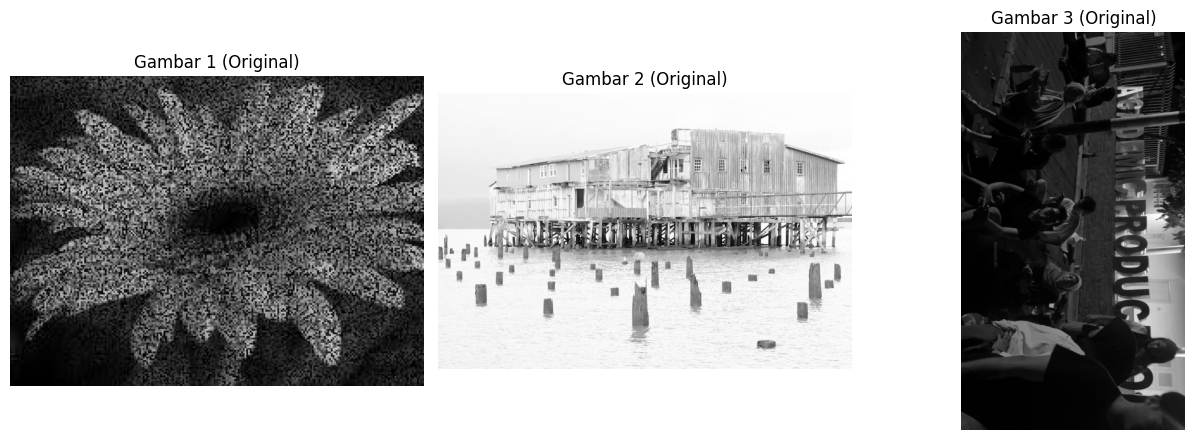

In [88]:
originals = [load_grayscale(p) for p in image_paths]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for i, im in enumerate(originals):
    axes[i].imshow(im, cmap='gray', vmin=0, vmax=255)
    axes[i].set_title(f'Gambar {i+1} (Original)')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

##Gamma (Power-Law) Transform

Rumus: $s = T(r) = c\, r^{\gamma}$, dengan $0 \le r \le 1$ dan $\gamma \ge 0$.
- $\gamma < 1$ → memperjelas detail area gelap (mirip log transform)
- $\gamma > 1$ → memperjelas detail area terang

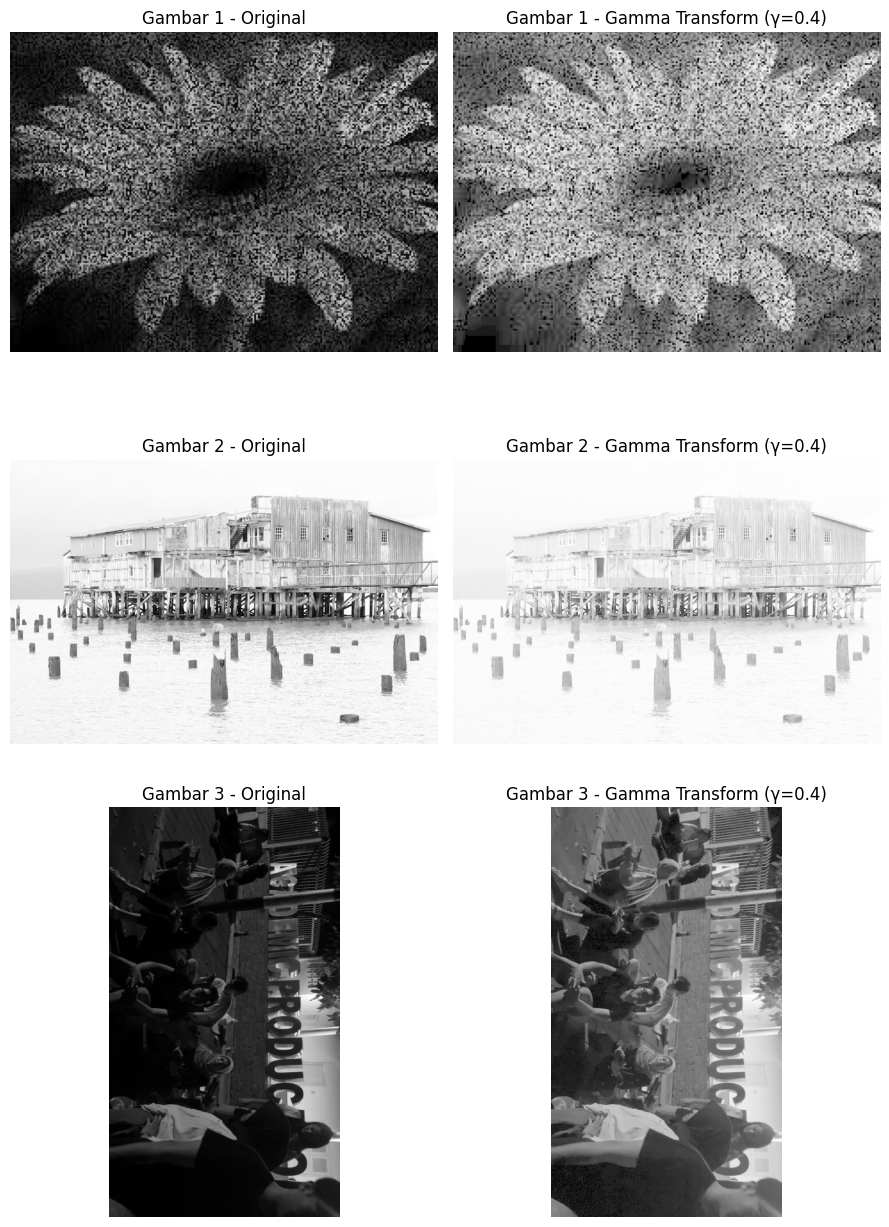

In [89]:
def gamma_transform(img, gamma=0.5, c=1.0):
    r = img.astype(float) / 255.0        # normalisasi ke [0,1]
    s = c * (r ** gamma)                  # s = c * r^gamma
    s = s / s.max() * 255.0 if s.max() > 0 else s * 255.0
    return np.clip(s, 0, 255).astype(np.uint8)


gamma_value = 0.4  # ubah nilai ini untuk eksperimen (contoh di slide: 0.3, 0.5, 0.7)
gamma_results = [gamma_transform(im, gamma=gamma_value) for im in originals]
show_grid(originals, gamma_results, f'Gamma Transform (γ={gamma_value})')

## Contrast Stretching

Rumus :
$$P_{out} = (P_{in} - Min)\left(\frac{b-a}{Max-Min}\right) + a,\quad a=0,\ b=255$$

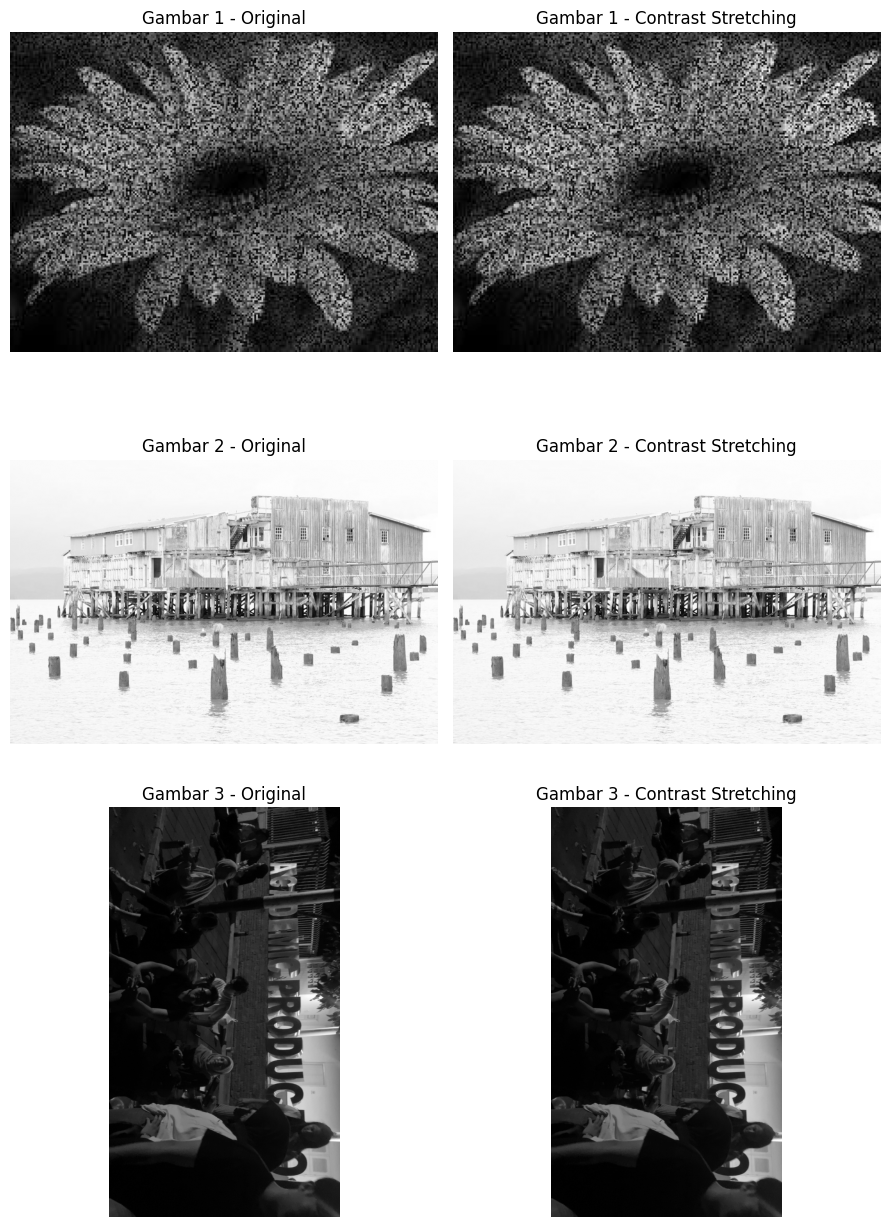

In [90]:
def contrast_stretching(img, a=0, b=255):
    Min = float(img.min())
    Max = float(img.max())
    if Max == Min:
        return img.copy()
    stretched = (img.astype(float) - Min) * ((b - a) / (Max - Min)) + a
    return np.clip(stretched, 0, 255).astype(np.uint8)


contrast_results = [contrast_stretching(im) for im in originals]
show_grid(originals, contrast_results, 'Contrast Stretching')

##Histogram Equalization

Proses: hitung histogram → PDF (P(L)) → CDF kumulatif → kalikan (L-1) → floor → gunakan sebagai lookup table pemetaan intensitas.

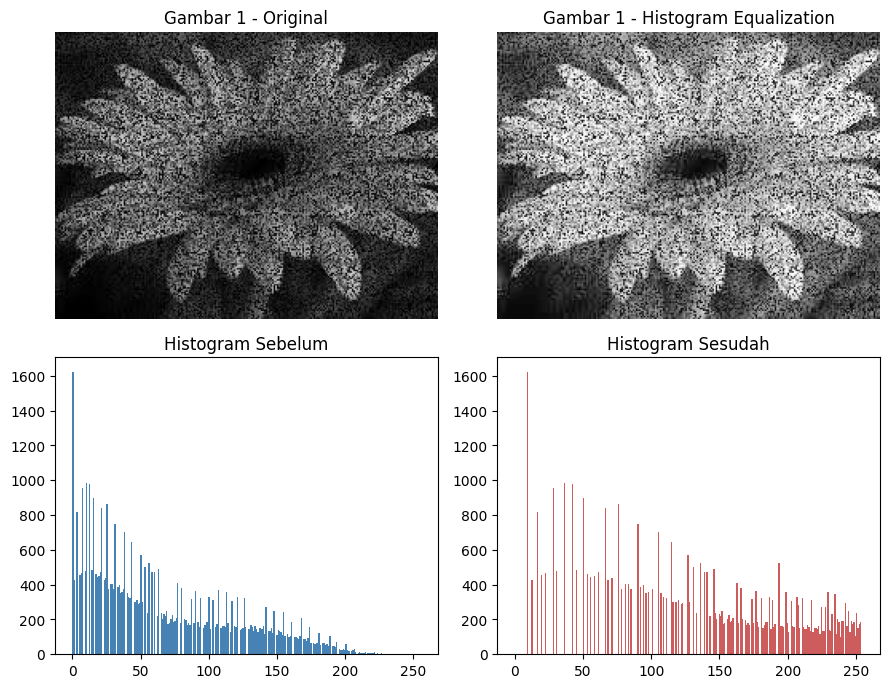

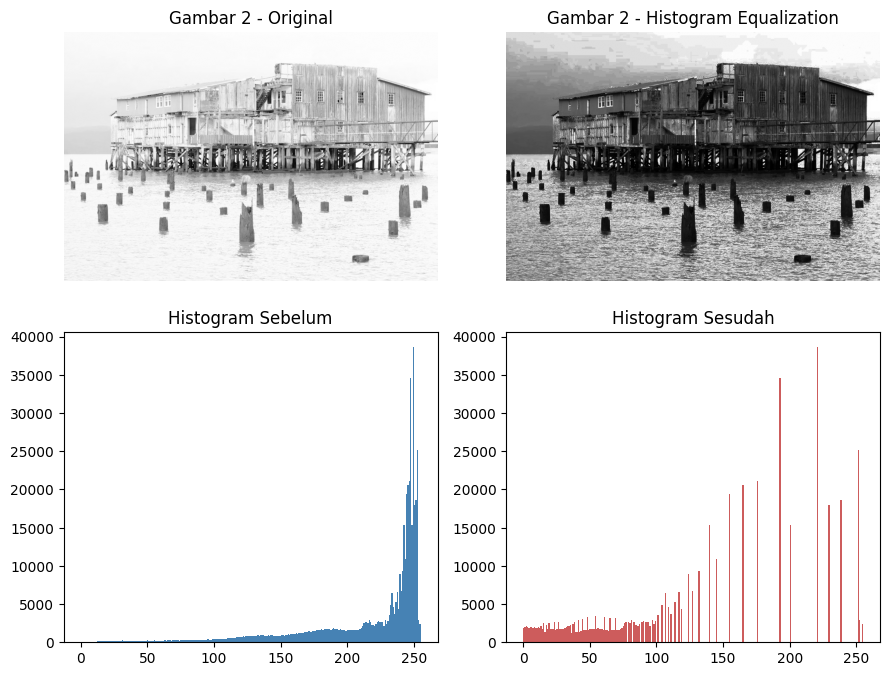

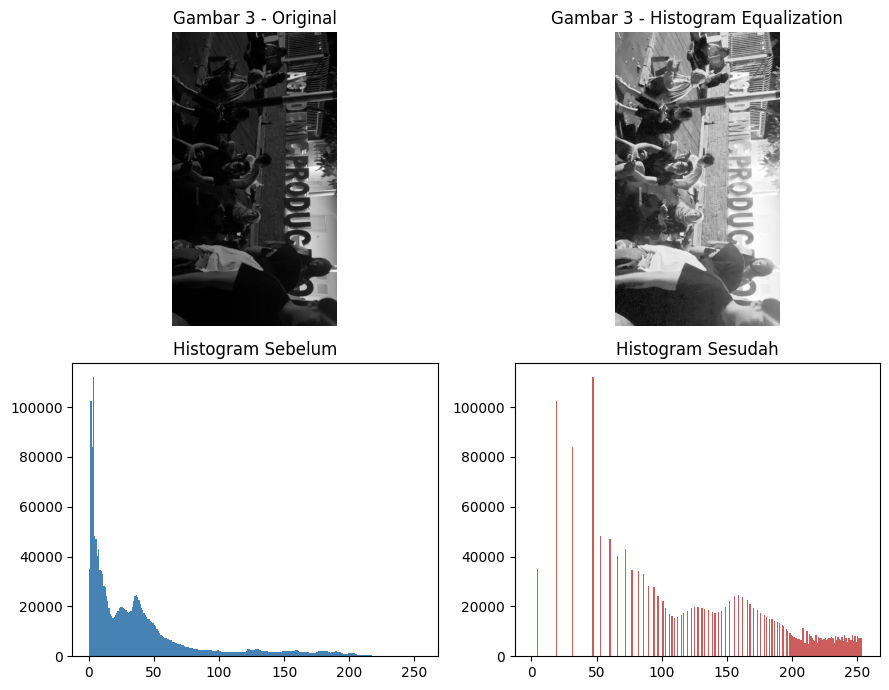

In [91]:
def histogram_equalization(img, L=256):
    # 1. Hitung histogram (frekuensi tiap gray level)
    hist = np.zeros(L)
    for val in img.flatten():
        hist[val] += 1

    # 2. PDF (Probability Density Function)
    pdf = hist / img.size

    # 3. CDF (Cumulative Probability)
    cdf = np.cumsum(pdf)

    # 4. Kalikan dengan (L-1) lalu floor -> lookup table
    mapping = np.floor(cdf * (L - 1)).astype(np.uint8)

    # 5. Terapkan mapping ke tiap pixel
    equalized = mapping[img]
    return equalized, hist


hist_eq_results = []
for i, im in enumerate(originals):
    eq_img, hist_before = histogram_equalization(im)
    hist_eq_results.append(eq_img)

    fig, axes = plt.subplots(2, 2, figsize=(9, 7))
    axes[0, 0].imshow(im, cmap='gray', vmin=0, vmax=255)
    axes[0, 0].set_title(f'Gambar {i+1} - Original')
    axes[0, 0].axis('off')
    axes[0, 1].imshow(eq_img, cmap='gray', vmin=0, vmax=255)
    axes[0, 1].set_title(f'Gambar {i+1} - Histogram Equalization')
    axes[0, 1].axis('off')
    axes[1, 0].hist(im.flatten(), bins=256, range=(0, 255), color='steelblue')
    axes[1, 0].set_title('Histogram Sebelum')
    axes[1, 1].hist(eq_img.flatten(), bins=256, range=(0, 255), color='indianred')
    axes[1, 1].set_title('Histogram Sesudah')
    plt.tight_layout()
    plt.show()

## Median Filter

Filter spasial non-linear: setiap pixel diganti dengan **nilai median** dari jendela ketetanggaan (misal 3x3). Cocok untuk mengurangi noise (salt & pepper) tanpa terlalu mengaburkan tepi.

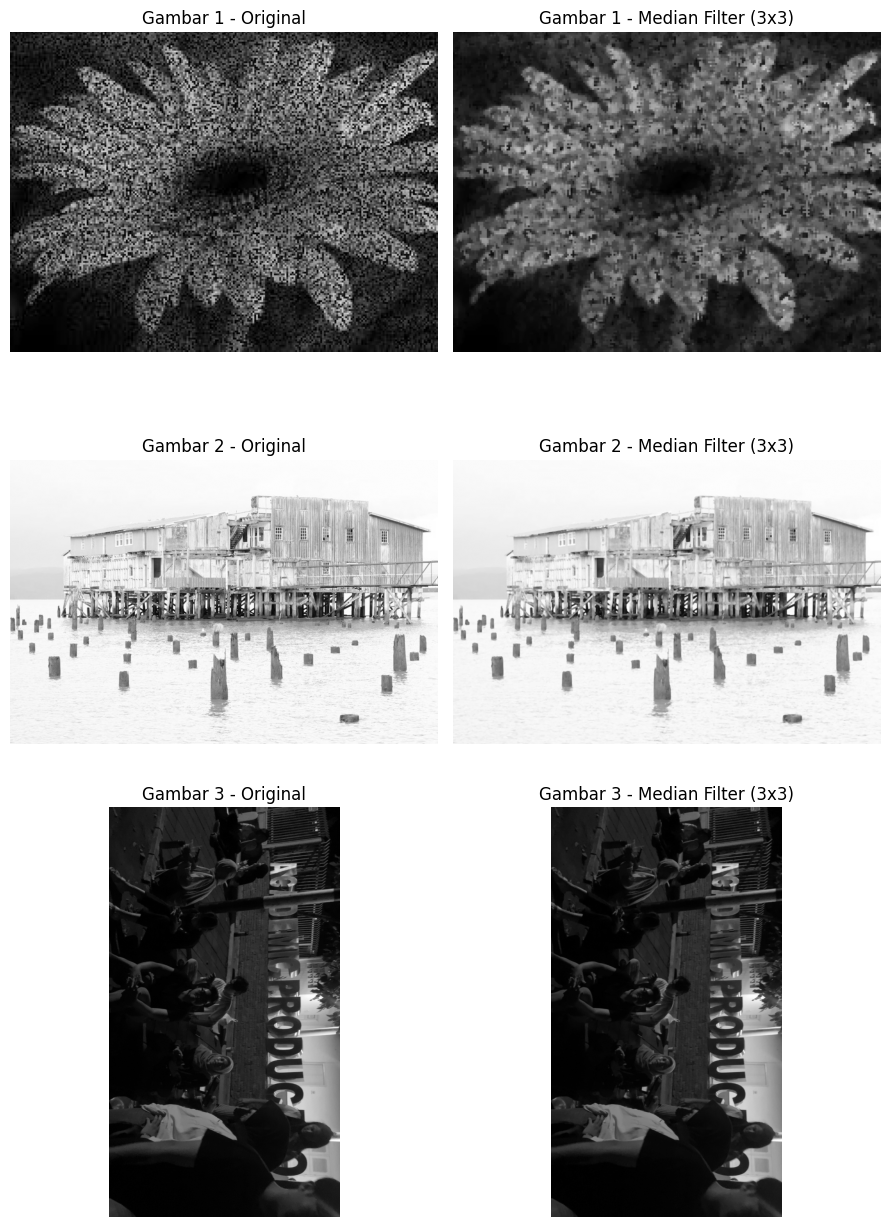

In [92]:
def median_filter(img, ksize=3):
    pad = ksize // 2
    padded = np.pad(img, pad, mode='edge')
    out = np.zeros_like(img)
    H, W = img.shape
    for i in range(H):
        for j in range(W):
            window = padded[i:i + ksize, j:j + ksize]
            out[i, j] = np.median(window)
    return out.astype(np.uint8)


median_results = [median_filter(im, ksize=3) for im in originals]
show_grid(originals, median_results, 'Median Filter (3x3)')

## Laplacian Sharpening

Kernel Laplacian (4-connected):
$$\begin{bmatrix}0 & 1 & 0\\ 1 & -4 & 1\\ 0 & 1 & 0\end{bmatrix}$$

Hasil sharpening: $g(x,y) = f(x,y) - \nabla^2 f(x,y)$ (tanda minus karena pusat kernel negatif).

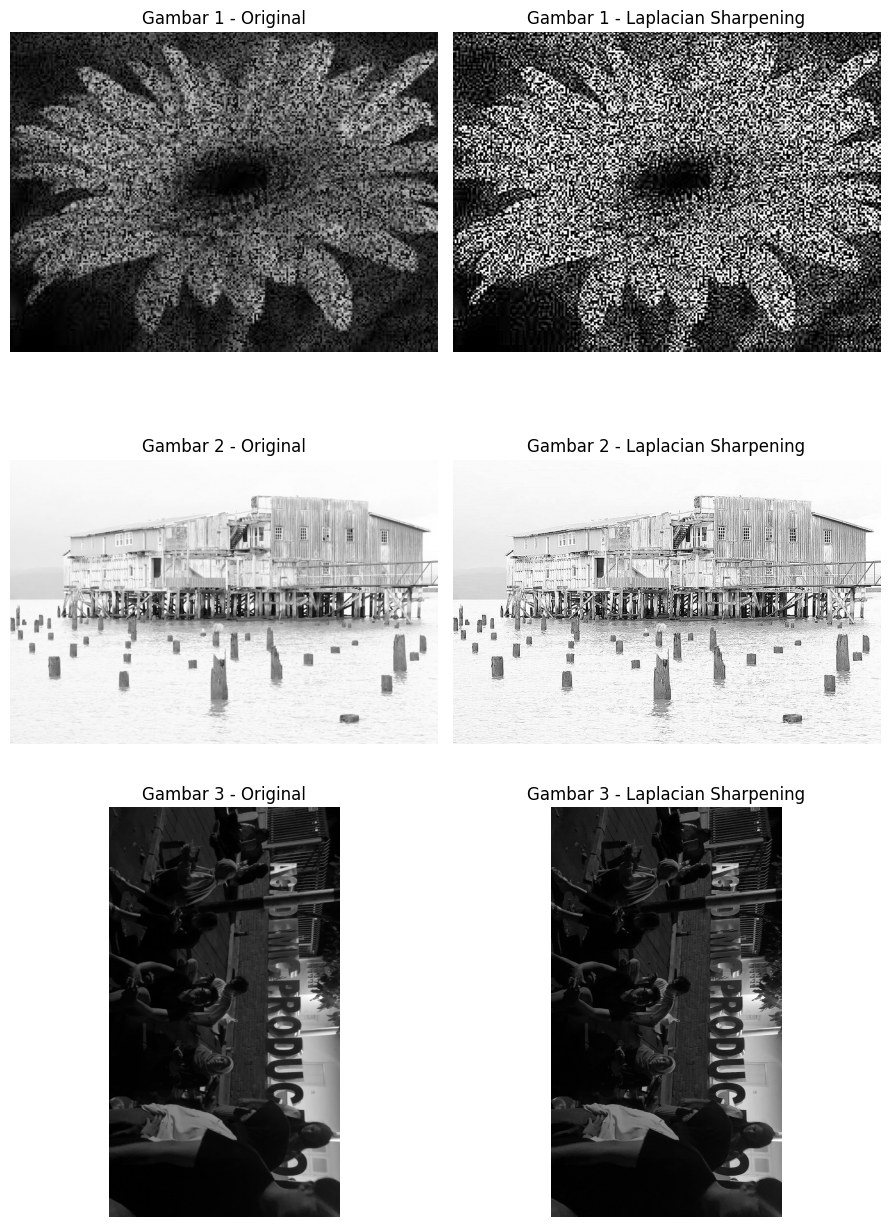

In [93]:
def laplacian_sharpening(img):
    kernel = np.array([[0, 1, 0],
                        [1, -4, 1],
                        [0, 1, 0]], dtype=float)
    laplacian = convolve2d(img, kernel)
    sharpened = img.astype(float) - laplacian
    return np.clip(sharpened, 0, 255).astype(np.uint8)


laplacian_results = [laplacian_sharpening(im) for im in originals]
show_grid(originals, laplacian_results, 'Laplacian Sharpening')

## Ringkasan: Perbandingan Semua Metode per Gambar

Menampilkan Original berdampingan dengan hasil ke-7 metode, untuk tiap gambar.

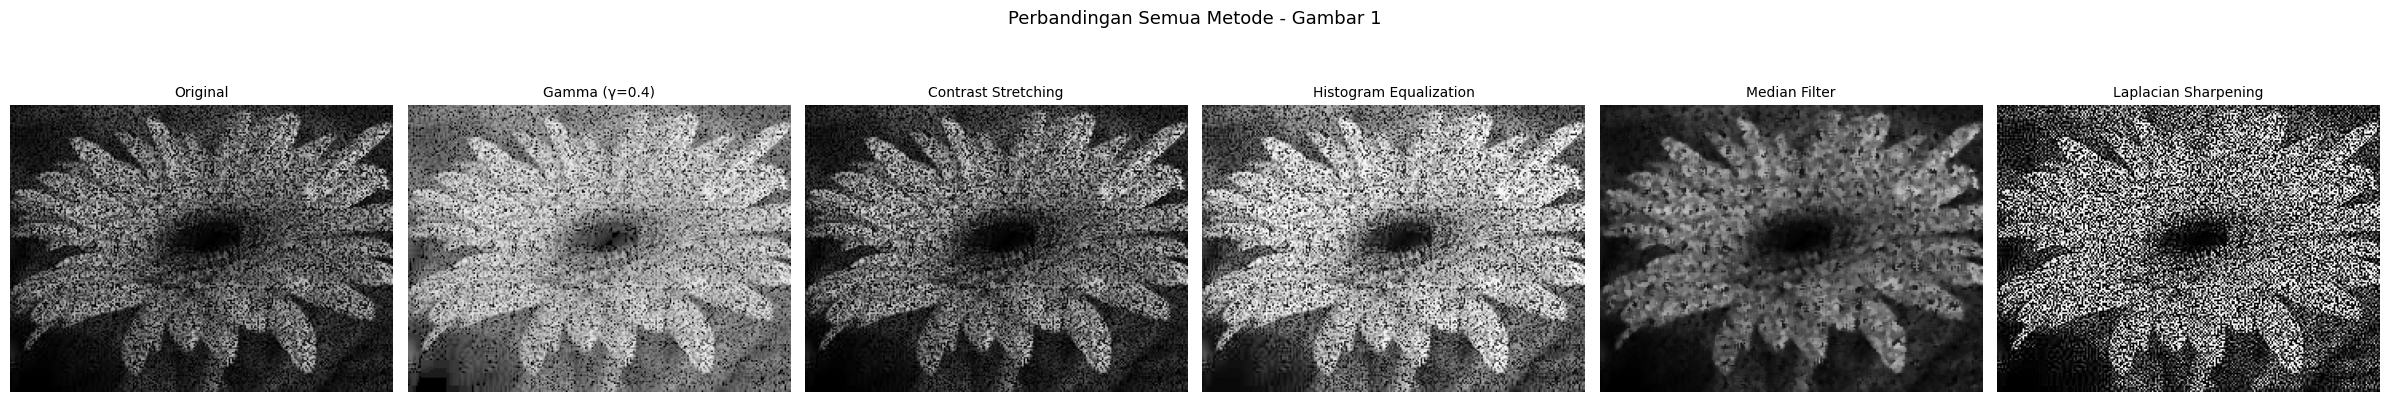

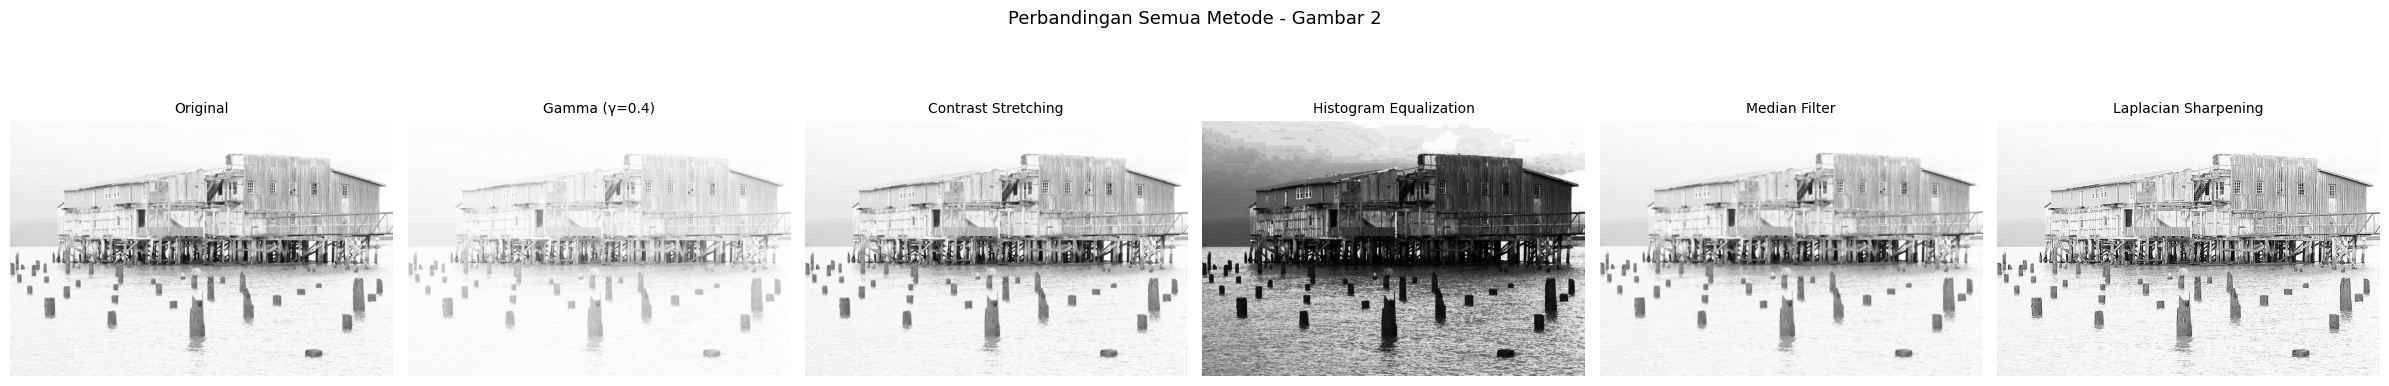

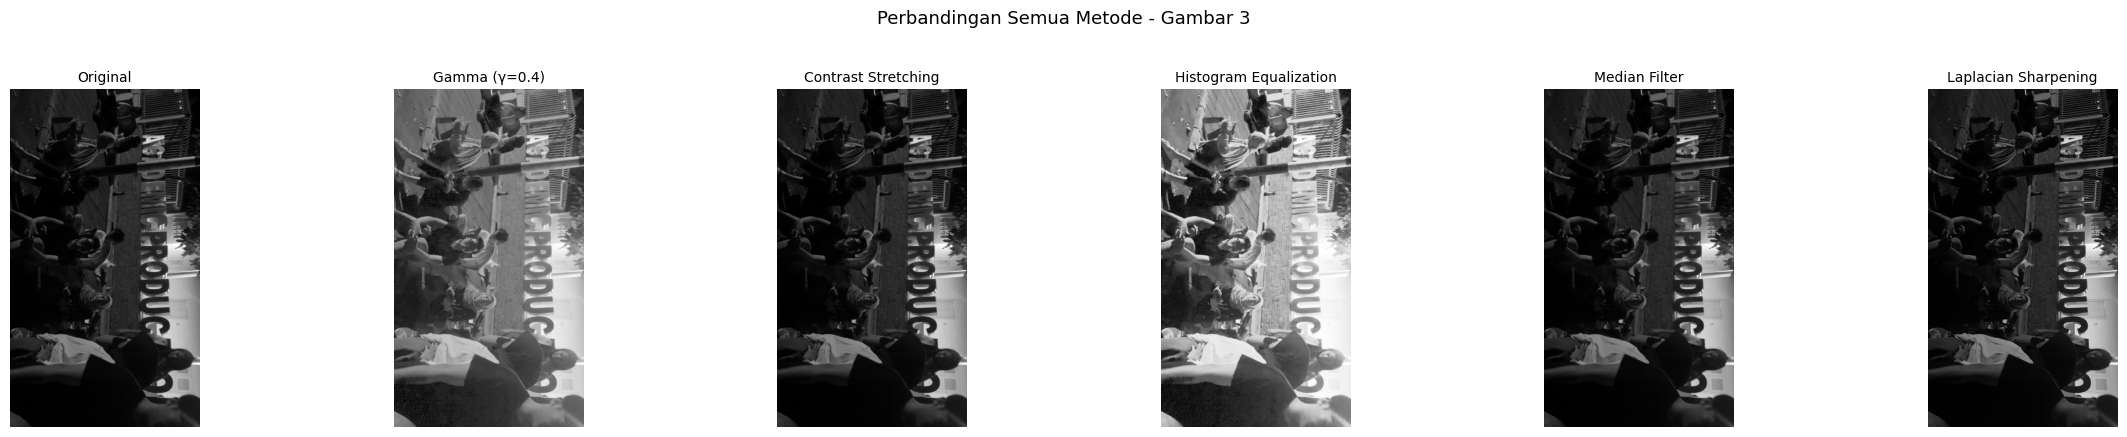

In [94]:
all_methods = [
    ('Original', originals),
    (f'Gamma (γ={gamma_value})', gamma_results),
    ('Contrast Stretching', contrast_results),
    ('Histogram Equalization', hist_eq_results),
    ('Median Filter', median_results),
    ('Laplacian Sharpening', laplacian_results),
]

n_images = len(originals)
n_methods = len(all_methods)

for i in range(n_images):
    fig, axes = plt.subplots(1, n_methods, figsize=(4 * n_methods, 4.2))
    for j, (name, results) in enumerate(all_methods):
        axes[j].imshow(results[i], cmap='gray', vmin=0, vmax=255)
        axes[j].set_title(name, fontsize=10)
        axes[j].axis('off')
    fig.suptitle(f'Perbandingan Semua Metode - Gambar {i+1}', fontsize=13, y=1.03)
    plt.tight_layout()
    plt.show()